c:\Users\dmitr\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\function_base.py:1242: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
c:\Users\dmitr\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
c:\Users\dmitr\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\function_base.py:1243: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
c:\Users\dmitr\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\function_base.py:1243: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
c:\Users\dmitr\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\function_base.py:1244: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
c:\Users\dmitr\AppData\Local\Programs\Python\

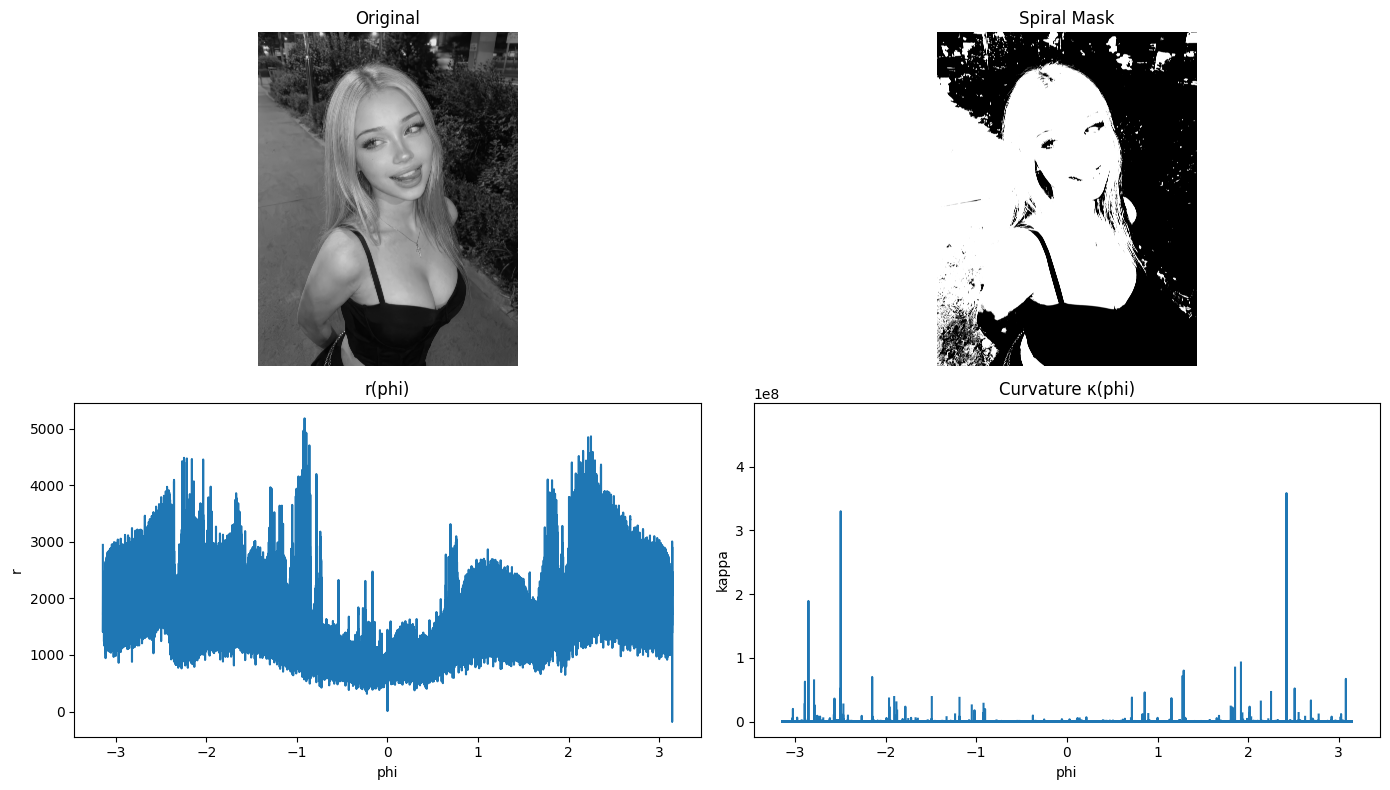

phi, r, kappa:
[[-3.14125298e+00  2.94400017e+03  1.15456528e-07]
 [-3.14125286e+00  2.94300017e+03  5.78068963e-08]
 [-3.14125275e+00  2.94200017e+03  2.16933662e-13]
 [-3.14125263e+00  2.94100017e+03  1.47952593e-13]
 [-3.14125252e+00  2.94000017e+03  1.93639769e-13]
 [-3.14125240e+00  2.93900017e+03  8.36868399e-14]
 [-3.14125229e+00  2.93800017e+03  2.98280229e-14]
 [-3.14125217e+00  2.93700017e+03  2.88781584e-14]
 [-3.14125205e+00  2.93600017e+03  9.00894991e-14]
 [-3.14125194e+00  2.93500017e+03  1.55232491e-13]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import savgol_filter

# -----------------------------
# 1. Загрузка изображения
# -----------------------------
def load_image(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = img.astype(np.float32) / 255.0
    return img


# -----------------------------
# 2. Выделение спирали
# -----------------------------
def extract_spiral_mask(img):
    # обратно в uint8
    img_uint8 = (img * 255).astype(np.uint8)

    blurred = cv2.GaussianBlur(img_uint8, (5, 5), 0)

    _, mask = cv2.threshold(
        blurred, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # приводим к 0/1
    mask = mask // 255

    return mask


# -----------------------------
# 3. Центр изображения
# -----------------------------
def get_center(img):
    h, w = img.shape
    return w // 2, h // 2


# -----------------------------
# 4. Перевод в полярные координаты
# -----------------------------
def cartesian_to_polar(mask, cx, cy):
    points = np.argwhere(mask > 0)

    y = points[:, 0] - cy
    x = points[:, 1] - cx

    r = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y, x)

    return r, phi


# -----------------------------
# 5. Обработка r(phi)
# -----------------------------
def process_curve(r, phi, bins=500):
    # биннинг по углу
    phi_bins = np.linspace(-np.pi, np.pi, bins)
    r_mean = np.zeros(bins-1)
    phi_center = (phi_bins[:-1] + phi_bins[1:]) / 2

    for i in range(len(phi_bins)-1):
        mask = (phi >= phi_bins[i]) & (phi < phi_bins[i+1])
        if np.any(mask):
            r_mean[i] = np.mean(r[mask])
        else:
            r_mean[i] = np.nan

    # удаляем nan
    valid = ~np.isnan(r_mean)
    phi = phi_center[valid]
    r = r_mean[valid]

    # сглаживание
    window = min(51, len(r)//2*2+1)
    if window < 5:
        window = 5

    r_smooth = savgol_filter(r, window, 3)

    return r_smooth, phi


# -----------------------------
# 6. Кривизна
# -----------------------------
def compute_curvature(r, phi):
    dr = np.gradient(r, phi)
    d2r = np.gradient(dr, phi)

    kappa = np.abs(
        r**2 + 2*dr**2 - r*d2r
    ) / (r**2 + dr**2)**1.5

    return kappa


# -----------------------------
# 7. Визуализация
# -----------------------------
def plot_all(img, mask, phi, r, kappa):

    plt.figure(figsize=(14, 8))

    # оригинал
    plt.subplot(2, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original")
    plt.axis("off")

    # маска
    plt.subplot(2, 2, 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Spiral Mask")
    plt.axis("off")

    # r(phi)
    plt.subplot(2, 2, 3)
    plt.plot(phi, r)
    plt.title("r(phi)")
    plt.xlabel("phi")
    plt.ylabel("r")

    # кривизна
    plt.subplot(2, 2, 4)
    plt.plot(phi, kappa)
    plt.title("Curvature κ(phi)")
    plt.xlabel("phi")
    plt.ylabel("kappa")

    plt.tight_layout()
    plt.show()


# -----------------------------
# 8. Основной запуск
# -----------------------------
def run_pipeline(image_path):
    img = load_image(image_path)

    mask = extract_spiral_mask(img)

    cx, cy = get_center(img)

    r, phi = cartesian_to_polar(mask, cx, cy)

    r_smooth, phi = process_curve(r, phi)

    kappa = compute_curvature(r_smooth, phi)

    plot_all(img, mask, phi, r_smooth, kappa)

    # таблица
    data = np.vstack([phi, r_smooth, kappa]).T

    return data


# -----------------------------
# ЗАПУСК
# -----------------------------``
if __name__ == "__main__":
    data = run_pipeline("input.png")

    print("phi, r, kappa:")
    print(data[:10])